# EDA: Wongnai restaurant reviews

Runs on the processed splits written by `python -m src.data`.

Star distribution and review length describe the data source, so they are computed on the
whole dataset. Word lists and example reviews use the train split only, so nothing from
val/test leaks into modeling decisions.

Figures are written to `results/figures/` and `report/figures/` as `eda_*.png`.

In [1]:
import re
import sys
import time
from collections import Counter
from pathlib import Path

ROOT = Path.cwd().parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import pandas as pd

from src import config, data, plotting

plotting.setup()
pd.set_option("display.max_colwidth", 200)

## 1. Splits

Check that the stratified split kept the class shares the same everywhere.

In [2]:
splits = {}
for name in ("train", "val", "test"):
    splits[name] = data.load_split(name)

rows = []
for name, part in splits.items():
    counts = part["label"].value_counts()
    row = {"split": name, "rows": len(part)}
    for label in config.LABELS:
        row[label] = f"{counts[label]:,} ({counts[label] / len(part):.1%})"
    rows.append(row)

split_table = pd.DataFrame(rows).set_index("split")
print(f"total rows: {sum(len(p) for p in splits.values()):,}")
split_table

total rows: 39,993


,rows,negative,neutral,positive
split,,,,
train,27995,"1,582 (5.7%)","8,519 (30.4%)","17,894 (63.9%)"
val,5999,339 (5.7%),"1,826 (30.4%)","3,834 (63.9%)"
test,5999,339 (5.7%),"1,826 (30.4%)","3,834 (63.9%)"


In [3]:
full = pd.concat(splits.values(), ignore_index=True)
train = splits["train"]
print(f"full {len(full):,} reviews, train {len(train):,} reviews")

full 39,993 reviews, train 27,995 reviews


## 2. Star and class distribution

      count     share
star                 
1       415  0.010377
2      1845  0.046133
3     12171  0.304328
4     18768  0.469282
5      6794  0.169880

          count     share
label                    
negative   2260  0.056510
neutral   12171  0.304328
positive  25562  0.639162


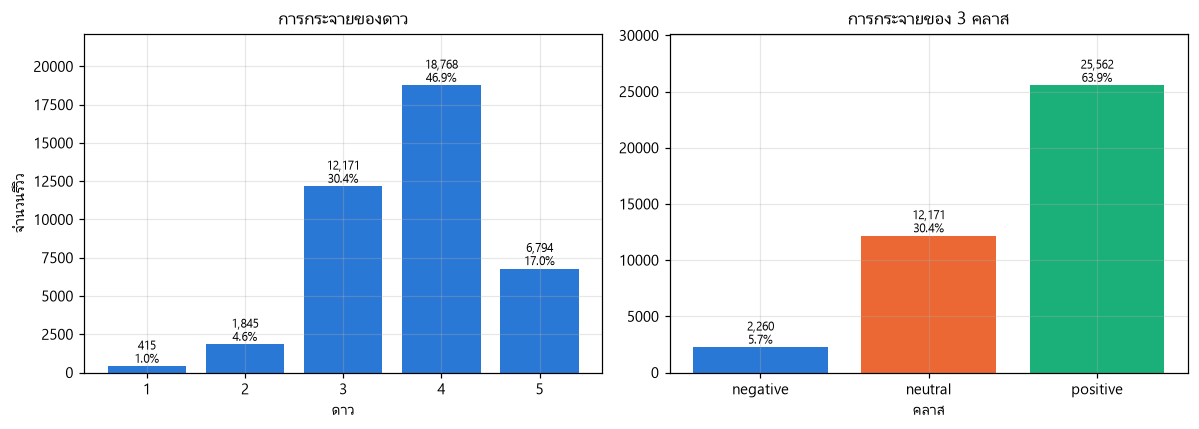

In [4]:
star_counts = full["star"].value_counts().sort_index()
label_counts = full["label"].value_counts().reindex(config.LABELS)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].bar(star_counts.index, star_counts.values, color=config.BAR_COLOR)
axes[0].set_xlabel("ดาว")
axes[0].set_ylabel("จำนวนรีวิว")
axes[0].set_title("การกระจายของดาว")
for star, count in star_counts.items():
    text = f"{count:,}\n{count / len(full):.1%}"
    axes[0].text(star, count, text, ha="center", va="bottom", fontsize=8)

label_colors = [config.LABEL_COLORS[label] for label in config.LABELS]
axes[1].bar(config.LABELS, label_counts.values, color=label_colors)
axes[1].set_xlabel("คลาส")
axes[1].set_title("การกระจายของ 3 คลาส")
for i, count in enumerate(label_counts.values):
    text = f"{count:,}\n{count / len(full):.1%}"
    axes[1].text(i, count, text, ha="center", va="bottom", fontsize=8)

for ax in axes:
    ax.margins(y=0.18)
fig.tight_layout()
plotting.save(fig, "eda_class_distribution")

print(pd.DataFrame({"count": star_counts, "share": star_counts / len(full)}))
print()
print(pd.DataFrame({"count": label_counts, "share": label_counts / len(full)}))

The majority class alone is ~64% of the data, so accuracy is a weak metric here.
A model that always answers `positive` would already score that. Macro-F1 is the
main metric because it gives the 5.6% negative class the same weight as the rest.

## 3. Review length in characters

In [5]:
full["n_chars"] = full["text"].str.len()
full["n_chars"].describe(percentiles=[0.5, 0.9, 0.95, 0.99]).round(0)

count    39993.0
mean       535.0
std        526.0
min         28.0
50%        368.0
90%       1011.0
95%       1402.0
99%       2665.0
max      20462.0
Name: n_chars, dtype: float64

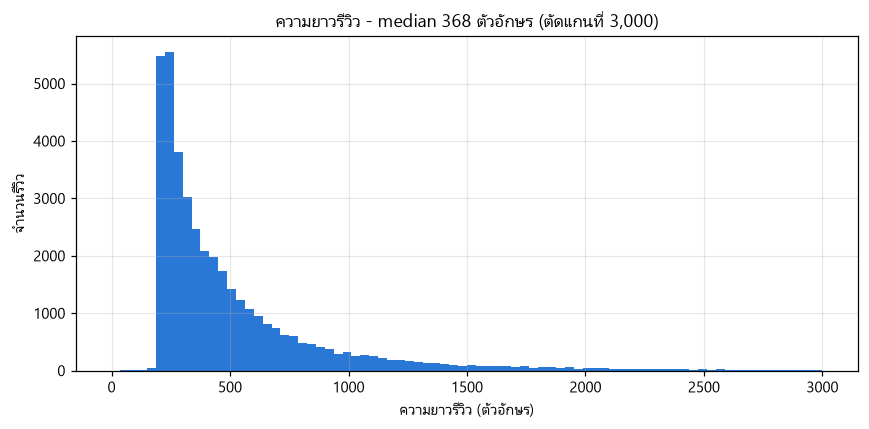

In [6]:
CHAR_AXIS_LIMIT = 3000

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(full["n_chars"], bins=80, range=(0, CHAR_AXIS_LIMIT), color=config.BAR_COLOR)
ax.set_xlabel("ความยาวรีวิว (ตัวอักษร)")
ax.set_ylabel("จำนวนรีวิว")
ax.set_title(
    f"ความยาวรีวิว - median {full['n_chars'].median():,.0f} ตัวอักษร"
    f" (ตัดแกนที่ {CHAR_AXIS_LIMIT:,})"
)
fig.tight_layout()
plotting.save(fig, "eda_length_chars")

## 4. Review length in bge-m3 tokens

This decides `EMBEDDING_MAX_LENGTH`. Anything above it gets cut off before the
embedding model sees it, so the share of reviews over the limit has to be reported.

In [7]:
from transformers import AutoTokenizer

tokenizer = AutoTokenizer.from_pretrained(config.EMBEDDING_MODEL)

texts = full["text"].tolist()
token_counts = []
started = time.perf_counter()
for start in range(0, len(texts), 1000):
    batch = texts[start:start + 1000]
    encoded = tokenizer(batch, add_special_tokens=True, truncation=False)
    for ids in encoded["input_ids"]:
        token_counts.append(len(ids))

full["n_tokens"] = token_counts
print(f"tokenized {len(texts):,} reviews in {time.perf_counter() - started:.1f}s")
full["n_tokens"].describe(percentiles=[0.5, 0.9, 0.95, 0.99]).round(0)

tokenized 39,993 reviews in 7.8s


count    39993.0
mean       167.0
std        160.0
min         10.0
50%        116.0
90%        316.0
95%        437.0
99%        810.0
max       6071.0
Name: n_tokens, dtype: float64

In [8]:
over_limit = full["n_tokens"] > config.EMBEDDING_MAX_LENGTH
print(f"max_length = {config.EMBEDDING_MAX_LENGTH}")
print(f"reviews over the limit: {over_limit.sum():,} ({over_limit.mean():.2%})")
print(f"tokens per character: {full['n_tokens'].sum() / full['n_chars'].sum():.3f}")
print()
print("share over the limit per class")
for label in config.LABELS:
    part = full[full["label"] == label]
    share = (part["n_tokens"] > config.EMBEDDING_MAX_LENGTH).mean()
    print(f"  {label:<9} {share:.2%}")

max_length = 512
reviews over the limit: 1,418 (3.55%)
tokens per character: 0.312

share over the limit per class
  negative  3.98%
  neutral   2.87%


  positive  3.83%


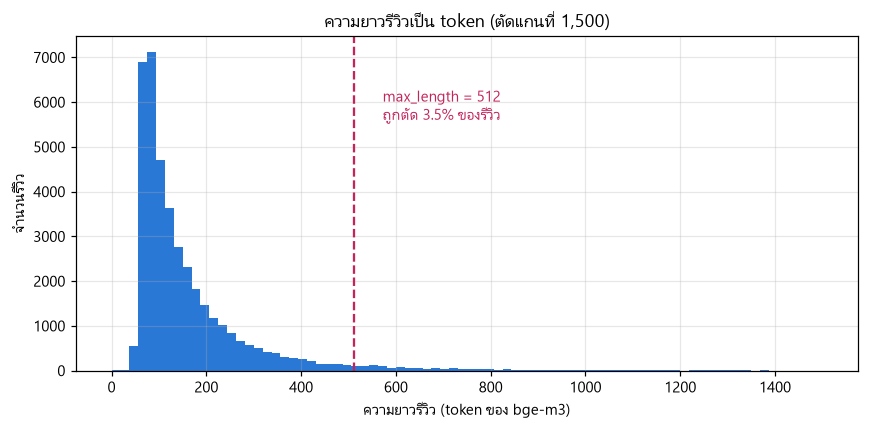

In [9]:
TOKEN_AXIS_LIMIT = 1500

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(full["n_tokens"], bins=80, range=(0, TOKEN_AXIS_LIMIT), color=config.BAR_COLOR)
ax.axvline(config.EMBEDDING_MAX_LENGTH, color="#c2255c", linestyle="--")
ax.annotate(
    f"max_length = {config.EMBEDDING_MAX_LENGTH}\nถูกตัด {over_limit.mean():.1%} ของรีวิว",
    xy=(config.EMBEDDING_MAX_LENGTH, 0),
    xytext=(config.EMBEDDING_MAX_LENGTH + 60, ax.get_ylim()[1] * 0.75),
    color="#c2255c",
)
ax.set_xlabel("ความยาวรีวิว (token ของ bge-m3)")
ax.set_ylabel("จำนวนรีวิว")
ax.set_title(f"ความยาวรีวิวเป็น token (ตัดแกนที่ {TOKEN_AXIS_LIMIT:,})")
fig.tight_layout()
plotting.save(fig, "eda_length_tokens")

## 5. Length per class

If one class is systematically longer, length itself carries signal and the model
may pick up on it instead of on sentiment.

,n_chars,n_tokens
label,,
negative,440.0,138.0
neutral,378.0,119.0
positive,358.0,113.0


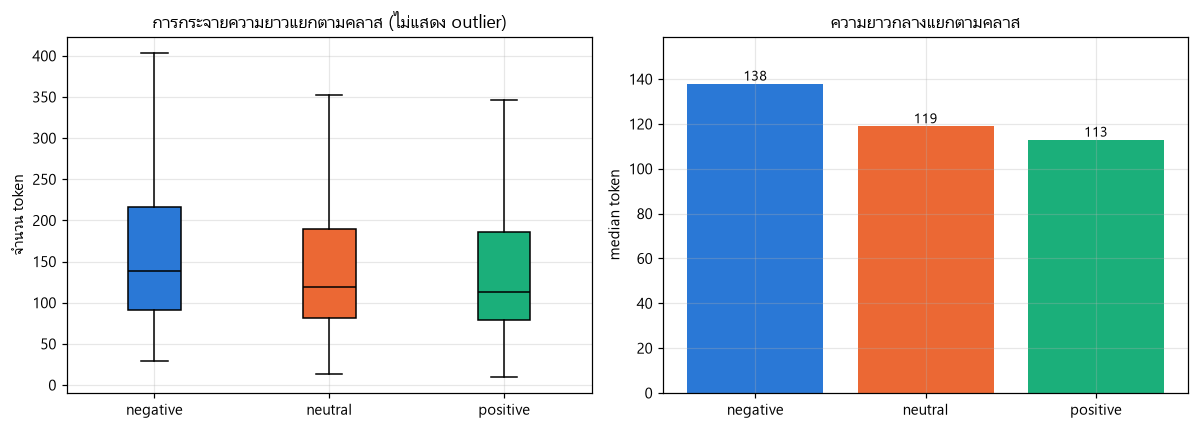

In [10]:
token_groups = []
for label in config.LABELS:
    token_groups.append(full.loc[full["label"] == label, "n_tokens"].to_numpy())

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

box = axes[0].boxplot(token_groups, showfliers=False, patch_artist=True)
for patch, label in zip(box["boxes"], config.LABELS):
    patch.set_facecolor(config.LABEL_COLORS[label])
for median in box["medians"]:
    median.set_color("black")
axes[0].set_xticks(range(1, len(config.LABELS) + 1))
axes[0].set_xticklabels(config.LABELS)
axes[0].set_ylabel("จำนวน token")
axes[0].set_title("การกระจายความยาวแยกตามคลาส (ไม่แสดง outlier)")

medians = []
for group in token_groups:
    medians.append(float(pd.Series(group).median()))
axes[1].bar(config.LABELS, medians, color=label_colors)
axes[1].set_ylabel("median token")
axes[1].set_title("ความยาวกลางแยกตามคลาส")
for i, value in enumerate(medians):
    axes[1].text(i, value, f"{value:,.0f}", ha="center", va="bottom", fontsize=9)
axes[1].margins(y=0.15)

fig.tight_layout()
plotting.save(fig, "eda_length_by_class")

summary = full.groupby("label")[["n_chars", "n_tokens"]].median()
summary.reindex(config.LABELS).round(0)

## 6. Frequent words per class (train only)

Tokenized with `newmm`, Thai stopwords removed. Counted as document frequency (in how
many reviews a word appears) rather than raw token count, so one long review repeating
a word cannot dominate and the shares stay comparable between classes of different size.

In [11]:
from pythainlp.corpus import thai_stopwords
from pythainlp.tokenize import word_tokenize

stopwords = set(thai_stopwords())
# Drop punctuation, emoji and single characters; keep Thai, Latin and digits
WORD_PATTERN = re.compile(r"^[฀-๿a-zA-Z0-9]{2,}$")

doc_freq = {}
n_reviews = {}
for label in config.LABELS:
    doc_freq[label] = Counter()
    n_reviews[label] = int((train["label"] == label).sum())

started = time.perf_counter()
for text, label in zip(train["text"], train["label"]):
    words = set()
    for token in word_tokenize(text, engine="newmm", keep_whitespace=False):
        token = token.strip().lower()
        if token in stopwords or not WORD_PATTERN.match(token):
            continue
        words.add(token)
    doc_freq[label].update(words)

vocabulary = set()
for label in config.LABELS:
    vocabulary.update(doc_freq[label])

print(f"tokenized {len(train):,} train reviews in {time.perf_counter() - started:.1f}s")
print(f"{len(vocabulary):,} distinct words after stopword and symbol filtering")

tokenized 27,995 train reviews in 39.9s
34,953 distinct words after stopword and symbol filtering


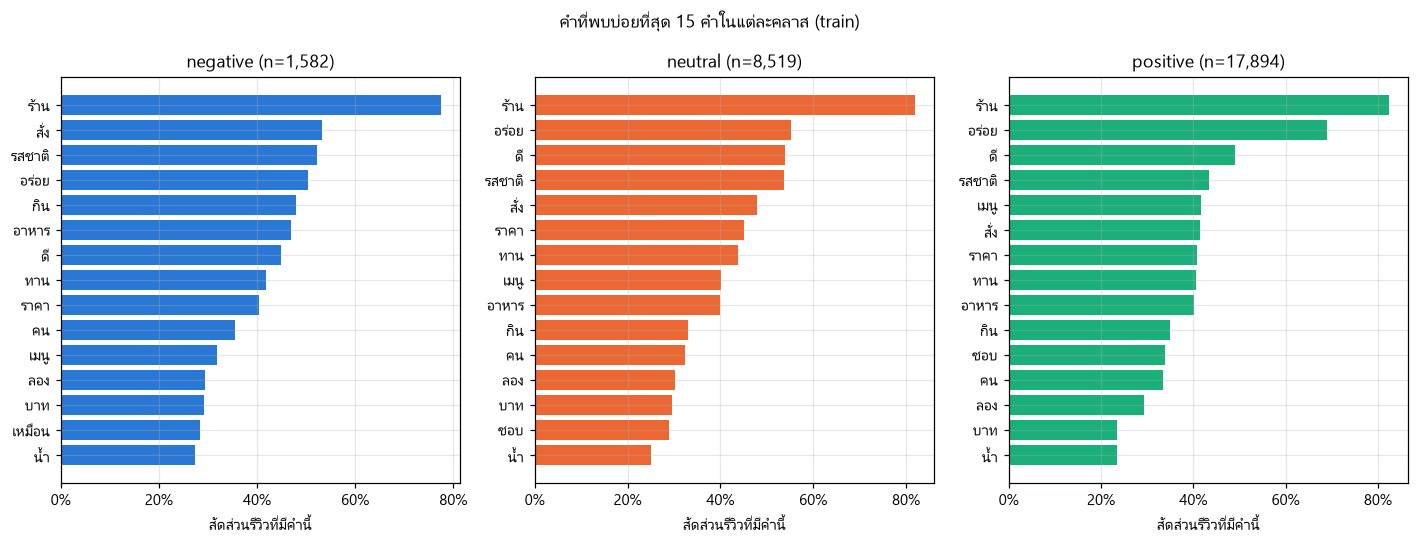

In [12]:
from matplotlib.ticker import PercentFormatter

TOP_N = 15

fig, axes = plt.subplots(1, 3, figsize=(13, 5))
for ax, label in zip(axes, config.LABELS):
    top = doc_freq[label].most_common(TOP_N)
    words = []
    shares = []
    for word, count in reversed(top):
        words.append(word)
        shares.append(count / n_reviews[label])
    ax.barh(words, shares, color=config.LABEL_COLORS[label])
    ax.set_title(f"{label} (n={n_reviews[label]:,})")
    ax.set_xlabel("สัดส่วนรีวิวที่มีคำนี้")
    ax.xaxis.set_major_formatter(PercentFormatter(xmax=1))

fig.suptitle(f"คำที่พบบ่อยที่สุด {TOP_N} คำในแต่ละคลาส (train)")
fig.tight_layout()
plotting.save(fig, "eda_top_words")

===== negative =====
  แย่มาก               x25.39  (พบใน 73 รีวิว = 4.6%)
  เสียความรู้สึก       x25.04  (พบใน 30 รีวิว = 1.9%)
  แย่                  x 7.22  (พบใน 151 รีวิว = 9.5%)
  เช็คบิล              x 6.23  (พบใน 44 รีวิว = 2.8%)
  เซ็ง                 x 5.99  (พบใน 33 รีวิว = 2.1%)
  เศษ                  x 4.86  (พบใน 30 รีวิว = 1.9%)
  ปรับปรุง             x 4.74  (พบใน 102 รีวิว = 6.4%)
  ตังค์                x 4.24  (พบใน 34 รีวิว = 2.1%)
  เงิน                 x 3.87  (พบใน 94 รีวิว = 5.9%)
  งั้น                 x 3.86  (พบใน 61 รีวิว = 3.9%)
  ทิ้ง                 x 3.83  (พบใน 39 รีวิว = 2.5%)
  คาดหวัง              x 3.77  (พบใน 42 รีวิว = 2.7%)
  คิดเงิน              x 3.69  (พบใน 36 รีวิว = 2.3%)
  ตัง                  x 3.46  (พบใน 34 รีวิว = 2.1%)
  ออเดอร์              x 3.46  (พบใน 65 รีวิว = 4.1%)

===== neutral =====
  สุภ                  x 3.92  (พบใน 36 รีวิว = 0.4%)
  พอใช้ได้             x 3.01  (พบใน 321 รีวิว = 3.8%)
  kfc                  x 2.74  (พบใน 

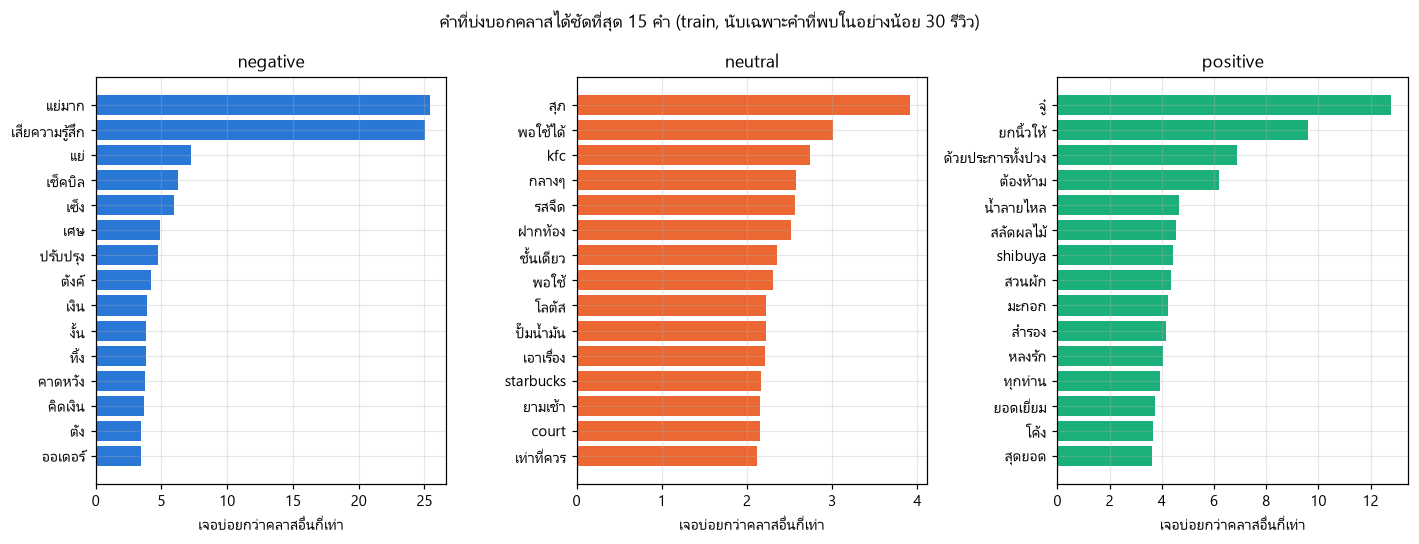

In [13]:
MIN_REVIEWS = 30

distinctive = {}
for label in config.LABELS:
    inside_reviews = n_reviews[label]
    outside_reviews = len(train) - inside_reviews
    scored = []
    for word, inside in doc_freq[label].items():
        if inside < MIN_REVIEWS:
            continue
        outside = 0
        for other in config.LABELS:
            if other != label:
                outside += doc_freq[other][word]
        share_in = inside / inside_reviews
        # +1 smoothing so a word that never appears outside the class does not blow up
        share_out = (outside + 1) / outside_reviews
        scored.append((share_in / share_out, word, inside))
    scored.sort(reverse=True)
    distinctive[label] = scored[:TOP_N]

fig, axes = plt.subplots(1, 3, figsize=(13, 5))
for ax, label in zip(axes, config.LABELS):
    words = []
    ratios = []
    for ratio, word, _ in reversed(distinctive[label]):
        words.append(word)
        ratios.append(ratio)
    ax.barh(words, ratios, color=config.LABEL_COLORS[label])
    ax.set_title(label)
    ax.set_xlabel("เจอบ่อยกว่าคลาสอื่นกี่เท่า")

fig.suptitle(
    f"คำที่บ่งบอกคลาสได้ชัดที่สุด {TOP_N} คำ"
    f" (train, นับเฉพาะคำที่พบในอย่างน้อย {MIN_REVIEWS} รีวิว)"
)
fig.tight_layout()
plotting.save(fig, "eda_distinctive_words")

for label in config.LABELS:
    print(f"===== {label} =====")
    for ratio, word, inside in distinctive[label]:
        share = inside / n_reviews[label]
        print(f"  {word:<20} x{ratio:>5.2f}  (พบใน {inside:,} รีวิว = {share:.1%})")
    print()

In [14]:
CHECK_WORDS = ["อร่อย", "ดี", "ชอบ", "แย่", "ผิดหวัง"]

print("share of reviews containing the word")
print(f"{'':<12}" + "".join(f"{label:>10}" for label in config.LABELS))
for word in CHECK_WORDS:
    cells = ""
    for label in config.LABELS:
        cells += f"{doc_freq[label][word] / n_reviews[label]:>10.1%}"
    print(f"{word:<12}{cells}")

# newmm splits "ไม่อร่อย" into "ไม่" + "อร่อย" and "ไม่" is a stopword, so a bag of
# words keeps the positive token and throws the negation away
print()
print("negation, counted on the raw string instead of on tokens")
for label in config.LABELS:
    part = train[train["label"] == label]
    plain = part["text"].str.contains("อร่อย").mean()
    negated = part["text"].str.contains("ไม่อร่อย").mean()
    print(f"  {label:<9} อร่อย {plain:>6.1%}    ไม่อร่อย {negated:>6.1%}")

share of reviews containing the word
              negative   neutral  positive
อร่อย            50.4%     55.3%     69.0%
ดี               44.9%     53.9%     49.0%
ชอบ              18.6%     28.9%     33.9%
แย่               9.5%      2.6%      0.7%
ผิดหวัง          10.9%      3.6%      5.4%

negation, counted on the raw string instead of on tokens
  negative  อร่อย  50.4%    ไม่อร่อย  16.2%
  neutral   อร่อย  55.4%    ไม่อร่อย   3.9%
  positive  อร่อย  69.2%    ไม่อร่อย   1.6%


The most frequent words are nearly the same list in all three classes, and the word
`อร่อย` ("tasty") is in 50% of the negative reviews against 69% of the positive ones.
Counting words on its own barely separates the classes.

Part of the reason is negation: 16% of negative reviews contain `ไม่อร่อย` ("not tasty"),
but `newmm` splits that into `ไม่` + `อร่อย` and `ไม่` is a stopword, so a bag of words
keeps the positive token and drops the negation. The TF-IDF baseline uses bigrams, which
recovers some of this, but it is the main reason to expect sentence embeddings to do better.

The distinctiveness ranking is more informative than raw frequency: negative reviews are
marked by complaint words (`แย่มาก`, `เสียความรู้สึก`, `เซ็ง`) and by billing and service
vocabulary (`เช็คบิล`, `คิดเงิน`, `ออเดอร์`), while neutral reviews are marked by hedging
(`พอใช้ได้`, `กลางๆ`, `เท่าที่ควร`, `รสจืด`) rather than by any negative word. That matches
the expectation that neutral will be the hardest class.

## 7. Example reviews (train only)

In [15]:
PREVIEW_CHARS = 350

for label in config.LABELS:
    part = train[train["label"] == label]
    print(f"===== {label} ({len(part):,} reviews) =====")
    for _, row in part.sample(3, random_state=config.SEED).iterrows():
        print(f"[{row['star']} ดาว, {len(row['text']):,} ตัวอักษร]")
        print(row["text"][:PREVIEW_CHARS])
        print()

===== negative (1,582 reviews) =====
[2 ดาว, 572 ตัวอักษร]
ร้านอยู่ในพลาซ่าคนละโซนกับเควิลเลจ เรียกว่านิฮอนมาจิ เพราะฉะนั้นถ้าท่านเข้าไปจอดในส่วนของเควิลเลจ เตรียมหาที่แสตมป์บัตรหรือเตรียมเสียตังค่าที่จอดรถไว้เลย ร้านหาไม่ยากแต่ป้ายชื่อร้านหายาก อยู่ข้างๆร้านเบเกอรี่ ถ้าท่านเป็นคนตัวสูงใหญ่ ไม่แนะนำให้ขึ้นไปทานชั้นสอง เพราะเพดานเตี้ยมาก และต้องนั่งกับพื้น พนักงานบริการดีครับ แต่รับออร์เดอร์อาจจะงงๆนิดนึง อ

[2 ดาว, 704 ตัวอักษร]
โคขุนโพนยางคำ เจ้านี้รีโนเวทไปมา เลยได้กินแต่เด็กละ วันนี้ไม่รู้จะกินไร ขอกลับมาลองอีกรอบ โดยร้านโคขุนนี้เขาคิดราคาเป็นจานตามสี เริ่มต้นที่ 19 บาท เป็นร้านสายพราน บริการกระทะเทปันยากิ หม้อต้ม(ต้มแซ่บ,ชาบู,สุกี้) และอาหารอีสานตามสั่ง พิกัด: ชั้นล่างสุด Fashion Island ตรงบันไดเลื่อนกลาง ติดโอโตยะ บริการ: พนง.นักเรียนดี แต่พนง.ประจำขี้ใช้นักเรียนไปหน่

[2 ดาว, 511 ตัวอักษร]
ไปทานสาขาที่ตลาดมา จากที่เคยทานเมื่อ 3 และ 5 ปีก่อนเคยอร่อยจนติดใจ มาคราวนี้มาถึงเชียงคานลงรถปุ๊ปมาทานเลย สั่งไส้หมูออริจินอลไป กะ หมูแดง สองอันเลยคันมาก แต่ต้องตกใจเมื่อพบว่าปาท่องโก๋เย็นมาก ร

## 8. What this means for the next steps

**Data.** 39,993 reviews after dropping 7 duplicates, split 27,995 / 5,999 / 5,999. The
class shares are identical in all three splits (5.7% / 30.4% / 63.9%), so the stratified
split worked.

**Metric.** Always answering `positive` already gives 63.9% accuracy, so accuracy is not
usable on its own. Macro-F1 stays the main metric and `class_weight="balanced"` is needed
wherever the model supports it. Negative is only 1,582 training reviews.

**max_length.** 3.55% of reviews are longer than 512 bge-m3 tokens (median 116, p95 437,
max 6,071). That is below the 5% threshold set in the plan, so `EMBEDDING_MAX_LENGTH`
stays at 512 and no decision is needed. Truncation is spread evenly over the classes
(negative 3.98%, neutral 2.87%, positive 3.83%), so it will not bias one class.
One Thai character is about 0.31 bge-m3 tokens.

**Length is weak signal.** Negative reviews are a bit longer (median 138 tokens vs 113 for
positive) but the distributions overlap almost completely, so length alone will not
classify anything.

**Why embeddings should beat TF-IDF.** The top-15 word lists are nearly identical across
classes and `อร่อย` appears in half of the negative reviews, largely because `newmm`
splits `ไม่อร่อย` and `ไม่` is dropped as a stopword. Word counts lose the negation that
the sentence embedding should keep.

**Expect neutral to be hardest.** Neutral reviews are marked by hedging (`พอใช้ได้`,
`กลางๆ`, `เท่าที่ควร`), not by their own vocabulary, so they sit between the other two
classes. The 3-star examples in section 7 contain both praise and complaints in the same
review.